# Module 5 – Evaluation Metrics
**Project:** Personalized TED Talks Recommendation System Using Machine Learning (Infosys Springboard Internship — Milestone 3)

## 1. Overview & Objectives
This notebook implements and executes **Module 5: Evaluation Metrics**, reusing the prepared dataset (`ted_talks_prepared.csv`) and the persisted Module 3 artifacts in `milestone2_outputs/`.

**Key Tasks Covered:**
1. **Project, Artifact & Leakage Audit:** Verify alignment between `ted_talks_prepared.csv` and `milestone2_outputs/`, and verify that `related_talk_ids` is never used in feature construction or ranking.
2. **Ground-Truth Construction:** Parse TED's `related_talk_ids` into clean proxy relevance labels (excluding self-links and out-of-dataset IDs).
3. **Evaluation Metrics:** Implement and verify **Precision@K**, **Recall@K**, **NDCG@K**, and **MAP@K** ($K \in \{5, 10\}$).
4. **Five-Approach Comparison:** Evaluate **Transcript-only TF-IDF**, **Tags-only TF-IDF**, **Combined TF-IDF (50:50)**, **Transcript-primary (Tags-fallback)**, and a **Popularity Baseline (Views)** on the exact same eligible queries.
5. **Collaborative Filtering Feasibility:** Audit user-level interaction availability and compare Content-Based vs. Collaborative Filtering trade-offs honestly.
6. **Visualizations & Model Selection:** Generate 6 diagnostic plots and justify final model selection based on balanced performance, catalog coverage, and interpretability.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from module5.metrics import (
    precision_at_k,
    recall_at_k,
    ndcg_at_k,
    average_precision_at_k,
    evaluate_single_query,
)
from module5.evaluate import (
    build_ground_truth,
    popularity_ranking,
    top_k_from_scores,
    verify_no_data_leakage,
    run_evaluation,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
print("Imports successful. Ready for Module 5 evaluation.")

Imports successful. Ready for Module 5 evaluation.


## 2. Dataset & Module 3 Artifact Audit
We inspect `ted_talks_prepared.csv` and verify row-by-row alignment with `milestone2_outputs/talk_index.csv` and the existing similarity matrices (`similarity_transcript.npy`, `similarity_tags.npy`, `similarity_combined.npy`). No TF-IDF or similarity matrices are rebuilt.

In [2]:
PROJECT_ROOT = Path(".").resolve()
DATA_PATH = PROJECT_ROOT / "ted_talks_prepared.csv"
M3_DIR = PROJECT_ROOT / "milestone2_outputs"
OUT_DIR = PROJECT_ROOT / "module5_outputs"

df = pd.read_csv(DATA_PATH, usecols=["talk_id", "title", "speaker_1", "views", "comments", "related_talk_ids"])
talk_index = pd.read_csv(M3_DIR / "talk_index.csv")

assert len(df) == len(talk_index) == 4005, "Unexpected row count"
assert (df["talk_id"].to_numpy() == talk_index["talk_id"].to_numpy()).all(), "ID alignment mismatch!"

print(f"Dataset loaded: {len(df)} talks | Unique talk IDs: {df['talk_id'].nunique()}")
print("Row alignment with milestone2_outputs/talk_index.csv: EXACT MATCH")
for fname in ["similarity_transcript.npy", "similarity_tags.npy", "similarity_combined.npy"]:
    arr = np.load(M3_DIR / fname, mmap_mode="r")
    print(f"  {fname:28} -> shape {arr.shape}, dtype {arr.dtype}")

leakage_audit = verify_no_data_leakage(M3_DIR, PROJECT_ROOT)
print("\n=== Data Leakage Audit ===")
for k, v in leakage_audit.items():
    print(f"  {k:32}: {v}")
assert not leakage_audit["leakage_detected"], "Data leakage detected!" 

Dataset loaded: 4005 talks | Unique talk IDs: 4005
Row alignment with milestone2_outputs/talk_index.csv: EXACT MATCH
  similarity_transcript.npy    -> shape (4005, 4005), dtype float32
  similarity_tags.npy          -> shape (4005, 4005), dtype float32
  similarity_combined.npy      -> shape (4005, 4005), dtype float32

=== Data Leakage Audit ===
  leakage_detected                : False
  features_used_for_tfidf         : ['transcript', 'topics']
  related_talk_ids_in_vectorizer  : False
  related_talk_ids_in_similarity  : False
  m3_transcript_matrix_shape      : [4005, 50000]
  m3_tag_matrix_shape             : [4005, 457]
  note                            : Verified: `related_talk_ids` is used strictly for offline proxy ground-truth evaluation and is completely excluded from TF-IDF fitting, similarity computation, and popularity ranking.


## 3. Ground-Truth Construction (`related_talk_ids` Proxy Labels)
Because the dataset contains no user click/watch logs, TED's editorial `related_talk_ids` field is used as **proxy relevance labels**.
- **Self-links removed:** Query talks cannot be relevant to themselves.
- **Out-of-dataset IDs removed:** Only targets present in the 4,005-talk catalog can be retrieved.
- **Caveat:** These represent editorial curation links, not actual user preference data.

In [3]:
ids = df["talk_id"].to_numpy()
id_to_idx = {int(tid): i for i, tid in enumerate(ids)}
gt, eligible, excluded, gt_stats = build_ground_truth(df, id_to_idx)

print("=== Ground Truth Proxy Summary ===")
for k, v in gt_stats.items():
    print(f"  {k:34}: {v}")

=== Ground Truth Proxy Summary ===
  total_talks                       : 4005
  eligible_queries                  : 4004
  excluded_queries                  : 1
  excluded_talk_ids                 : [14610]
  raw_links_parsed                  : 23915
  self_links_removed                : 4
  out_of_dataset_links_removed      : 122
  mean_relevant_per_eligible_query  : 5.9413
  min_relevant_per_eligible_query   : 1
  max_relevant_per_eligible_query   : 6
  ground_truth_note                 : Proxy relevance labels derived from TED's editorial 'related_talk_ids'. These represent editorial curation links rather than actual user click/watch feedback.


## 4. Evaluation Metrics Implementation & Sanity Verification
For each eligible query $q$ with relevant set $R_q$ and sanitized top-$K$ list $\hat{L}_q$ (deduplicated, $q \notin \hat{L}_q$):
- **Precision@K** $= \frac{1}{K} \sum_{j=1}^{m} \text{rel}_j$
- **Recall@K** $= \frac{1}{|R_q|} \sum_{j=1}^{m} \text{rel}_j$
- **NDCG@K** $= \frac{\text{DCG@K}}{\text{IDCG@K}}$, where $\text{DCG@K} = \sum_{j=1}^{m} \frac{\text{rel}_j}{\log_2(j+1)}$
- **MAP@K** $= \frac{1}{|Q|} \sum_{q \in Q} \text{AP@K}(q)$, where $\text{AP@K}(q) = \frac{1}{\min(K, |R_q|)} \sum_{j=1}^{m} \text{Precision@}j(q) \cdot \text{rel}_j$

Below we verify the metric functions on a hand-calculated example and critical edge cases (empty ground truth, duplicates, self-recommendations).

In [4]:
# Hand-calculated sanity check
recs_ex = [10, 99, 20, 88, 77]
rel_ex = {10, 20, 30}
res_ex = evaluate_single_query(recs_ex, rel_ex, k=5)
print("Hand-calculated example (hits at ranks 1 & 3, |rel|=3):", {k: round(v, 4) for k, v in res_ex.items()})

# Edge cases
print("Empty ground truth ->", evaluate_single_query([10, 20], set(), k=5))
print("Self-item excluded ->", evaluate_single_query([10, 20, 30, 40, 50, 60], {10, 20, 30}, k=5, query_item=10))
print("Duplicates removed ->", evaluate_single_query([10, 10, 10, 20, 99], {10, 20}, k=5))

Hand-calculated example (hits at ranks 1 & 3, |rel|=3): {'precision@5': 0.4, 'recall@5': 0.6667, 'ndcg@5': 0.7039, 'ap@5': 0.5556}
Empty ground truth -> {'precision@5': 0.0, 'recall@5': 0.0, 'ndcg@5': 0.0, 'ap@5': 0.0}
Self-item excluded -> {'precision@5': 0.4, 'recall@5': 0.6666666666666666, 'ndcg@5': 0.7653606369886217, 'ap@5': 0.6666666666666666}
Duplicates removed -> {'precision@5': 0.4, 'recall@5': 1.0, 'ndcg@5': 1.0, 'ap@5': 1.0}


## 5. Multi-Approach Evaluation ($K = 5$ and $K = 10$)
We evaluate all five approaches against the exact same **4,004 eligible queries**, strictly excluding the query talk itself from every recommendation list:
1. **Transcript-only TF-IDF**
2. **Tags-only TF-IDF**
3. **Combined TF-IDF (50:50)**
4. **Transcript-primary (Tags-fallback):** uses transcript similarity when available, and falls back to tag similarity when transcript similarity is unavailable (e.g., the 5 empty-transcript talks).
5. **Popularity Baseline (Views):** ranks all other talks by descending `views`, strictly excluding the query talk.

In [5]:
meta = run_evaluation(PROJECT_ROOT)
summary_df = pd.read_csv(OUT_DIR / "evaluation_summary.csv")
comparison_df = pd.read_csv(OUT_DIR / "model_comparison.csv")

print(f"=== Evaluation Summary Table (N = {meta['ground_truth_stats']['eligible_queries']} Eligible Queries, {meta['ground_truth_stats']['excluded_queries']} Excluded) ===")
print(f"Tags-fallback triggered for {meta['tags_fallback_queries_triggered']} queries without usable transcript similarity.")
display(summary_df)

print("\n=== Extended Model Comparison ===")
display(comparison_df[["approach", "precision@5", "recall@5", "ndcg@5", "map@5", "precision@10", "recall@10", "ndcg@10", "map@10", "interpretability"]])

=== Evaluation Summary Table (N = 4004 Eligible Queries, 1 Excluded) ===
Tags-fallback triggered for 5 queries without usable transcript similarity.


,approach,evaluated_queries,excluded_queries,precision@5,recall@5,ndcg@5,map@5,hit_rate@5,precision@10,recall@10,ndcg@10,map@10,hit_rate@10
0,Transcript-only TF-IDF,4004,1,0.3000,0.2522,0.3410,0.2299,0.7995,0.2125,0.3571,0.3669,0.2309,0.8861
1,Tags-only TF-IDF,4004,1,0.1533,0.1289,0.1696,0.1012,0.5250,0.1184,0.1991,0.1928,0.1042,0.6651
2,Combined TF-IDF (50:50),4004,1,0.1932,0.1624,0.2157,0.1335,0.6141,0.1455,0.2446,0.2412,0.1372,0.7415
3,Transcript-primary (Tags-fallback),4004,1,0.3001,0.2523,0.3412,0.2299,0.8000,0.2126,0.3574,0.3671,0.2310,0.8871
4,Popularity Baseline (Views),4004,1,0.0044,0.0037,0.0050,0.0025,0.0217,0.0030,0.0051,0.0053,0.0023,0.0295



=== Extended Model Comparison ===


,approach,precision@5,recall@5,ndcg@5,map@5,precision@10,recall@10,ndcg@10,map@10,interpretability
0,Transcript-only TF-IDF,0.3000,0.2522,0.3410,0.2299,0.2125,0.3571,0.3669,0.2309,High (inspectable n-gram term overlap)
1,Tags-only TF-IDF,0.1533,0.1289,0.1696,0.1012,0.1184,0.1991,0.1928,0.1042,Very High (explicit categorical topics)
2,Combined TF-IDF (50:50),0.1932,0.1624,0.2157,0.1335,0.1455,0.2446,0.2412,0.1372,High (decomposes into transcript + tag similar...
3,Transcript-primary (Tags-fallback),0.3001,0.2523,0.3412,0.2299,0.2126,0.3574,0.3671,0.2310,High (transcript n-grams with explicit tag fal...
4,Popularity Baseline (Views),0.0044,0.0037,0.0050,0.0025,0.0030,0.0051,0.0053,0.0023,Trivial (global view count ranking)


## 6. Collaborative Filtering Feasibility Analysis
We inspect the project's interaction audit (`collaborative_filtering_feasibility.json`) and summarize the structural trade-offs between **Content-Based Filtering** and **Collaborative Filtering** given the available dataset.

In [6]:
cf_info = json.loads((OUT_DIR / "collaborative_filtering_feasibility.json").read_text(encoding="utf-8"))
print("Genuine user-item interactions found:", cf_info["genuine_user_item_interactions_found"])
print("Collaborative filtering implemented :", cf_info["collaborative_filtering_implemented"])
print("Reason:", cf_info["reason"])

cf_table = pd.DataFrame(cf_info["comparison_summary"]).T
display(cf_table)

Genuine user-item interactions found: False
Collaborative filtering implemented : False
Reason: The dataset contains 4,005 talk-level catalog rows with aggregate popularity metrics ('views', 'comments'), but zero user IDs, session logs, explicit ratings, or individual watch histories. Without a genuine bipartite user-item interaction matrix, Collaborative Filtering cannot be trained or evaluated. No synthetic users or fake interactions were fabricated.


,data_requirements,cold_start,personalization,explainability
Content-Based Filtering,"Item metadata, transcripts, topic tags (all av...",Works immediately for new talks with text/tags...,Content/query-driven; aligns with explicit tal...,High (shared TF-IDF terms and matching topic t...
Collaborative Filtering,Bipartite user-item interactions (unavailable ...,Suffers from both new-user and new-item cold-s...,Strong serendipity & latent taste modeling whe...,Moderate to Low (neighborhood or latent factor...


## 7. Evaluation Visualizations
All 6 visualizations below are generated directly from the computed evaluation metrics saved in `module5_outputs/`.

--- 01_precision_at_k_comparison.png ---


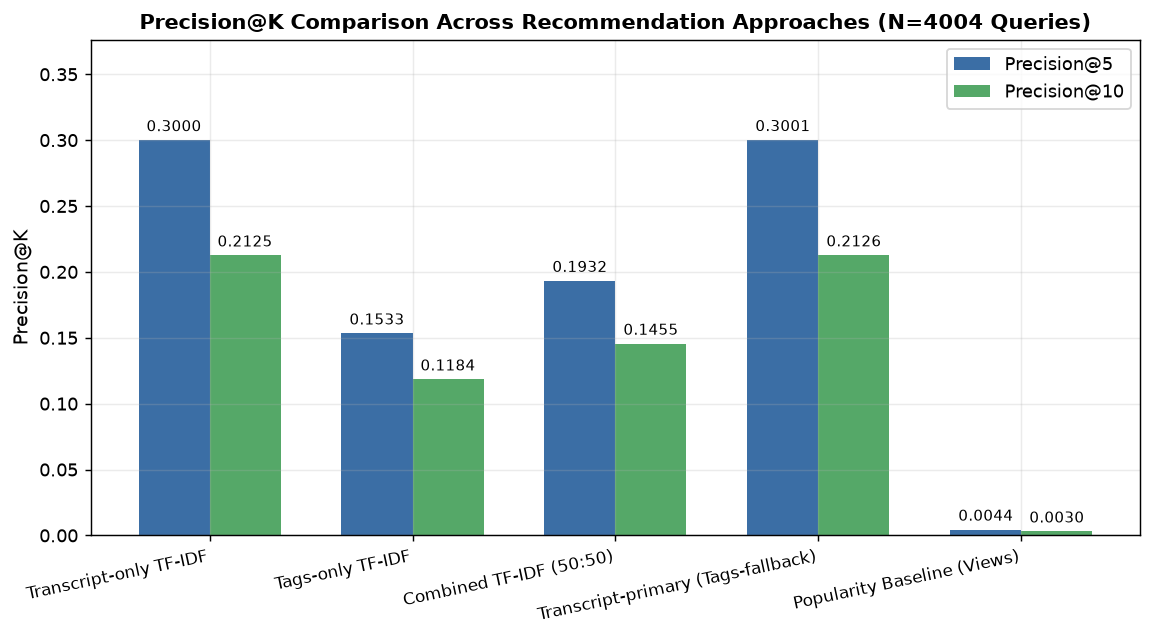

--- 02_recall_at_k_comparison.png ---


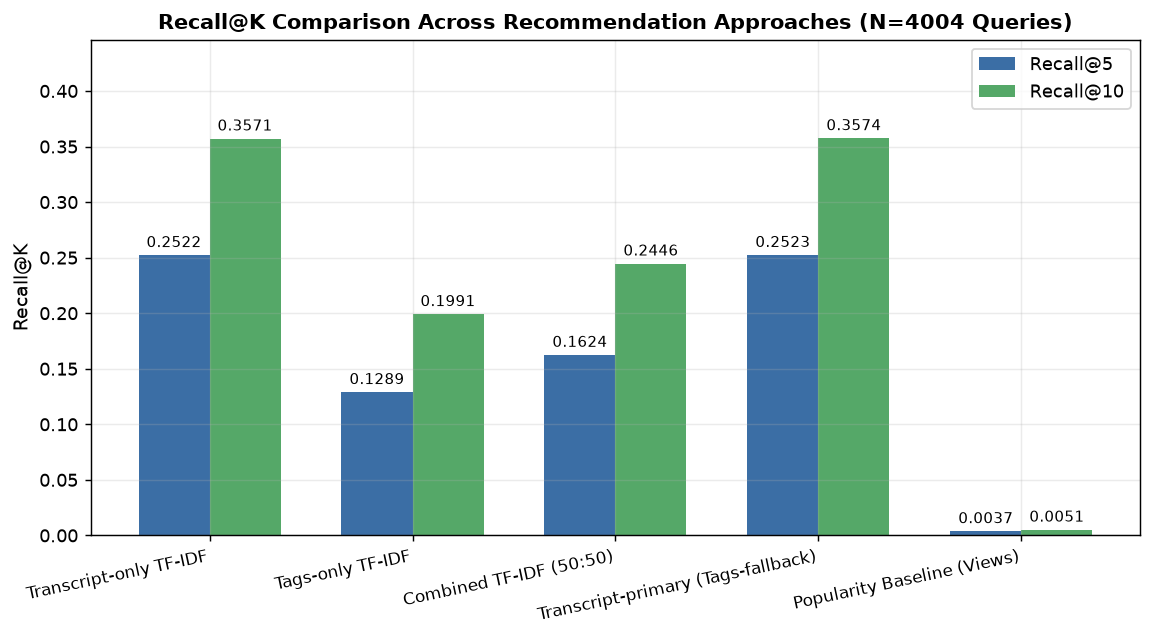

--- 03_ndcg_at_k_comparison.png ---


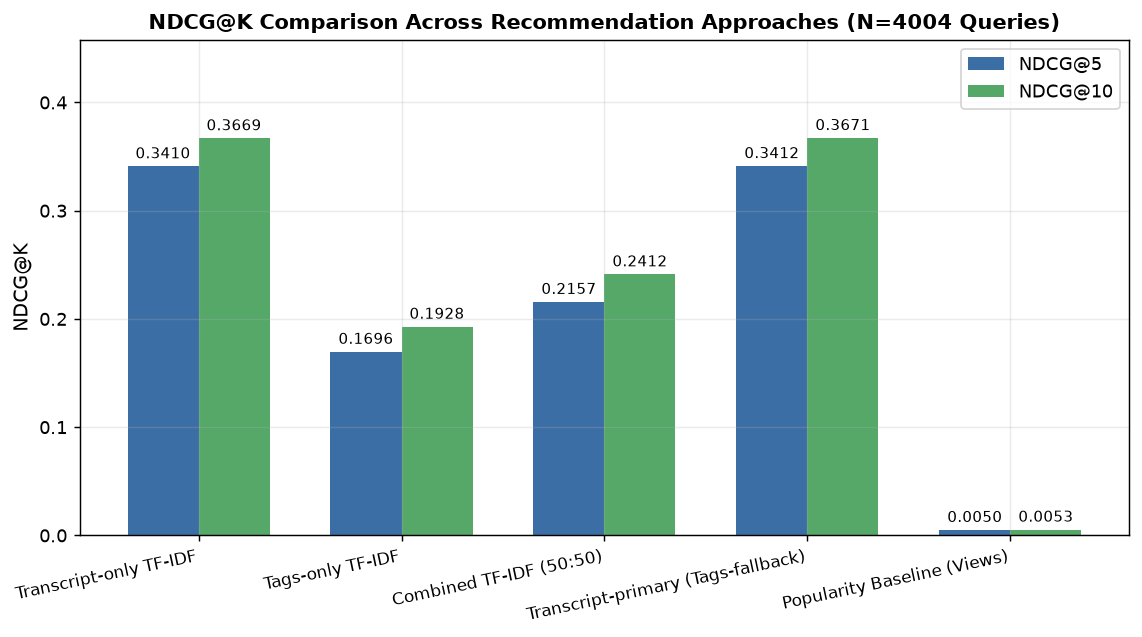

--- 04_map_at_k_comparison.png ---


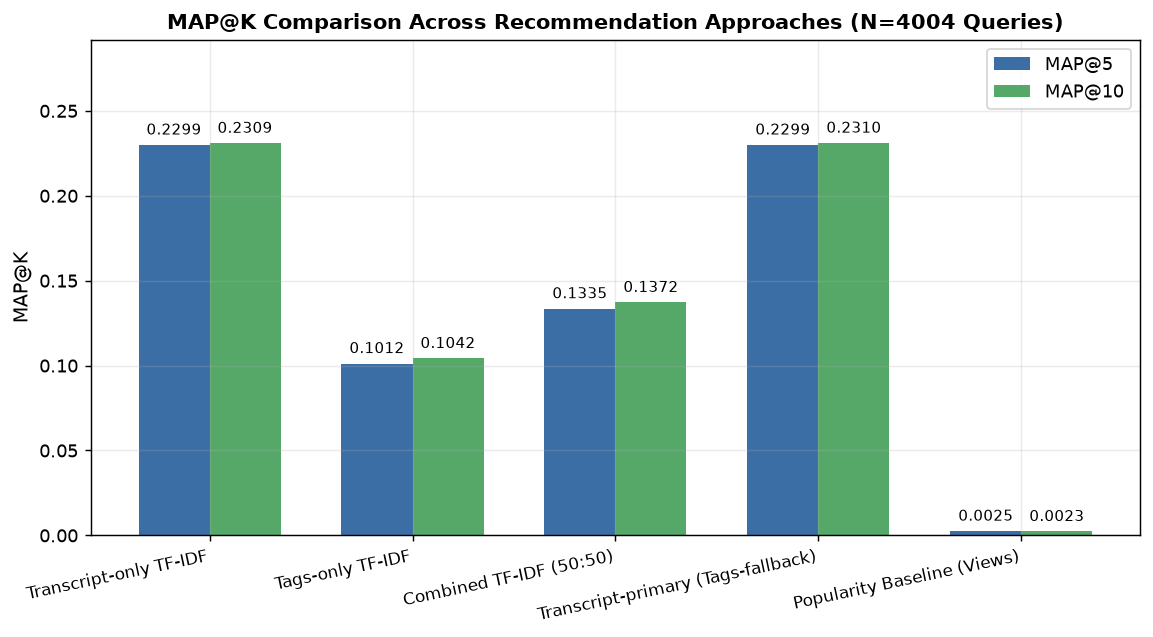

--- 05_overall_model_comparison.png ---


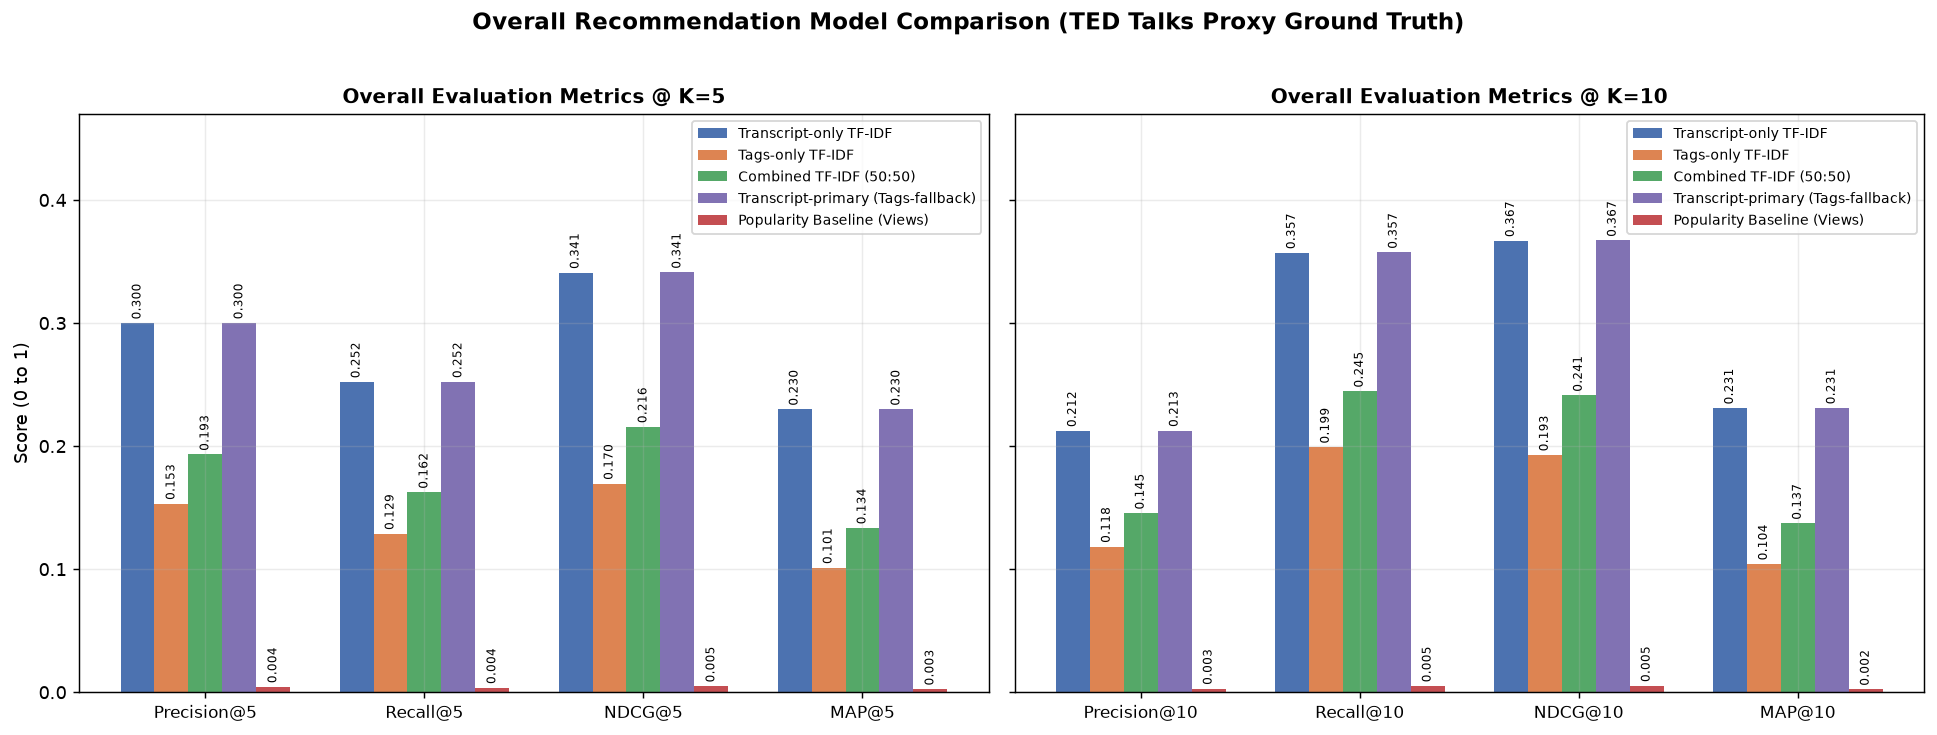

--- 06_approach_tradeoffs.png ---


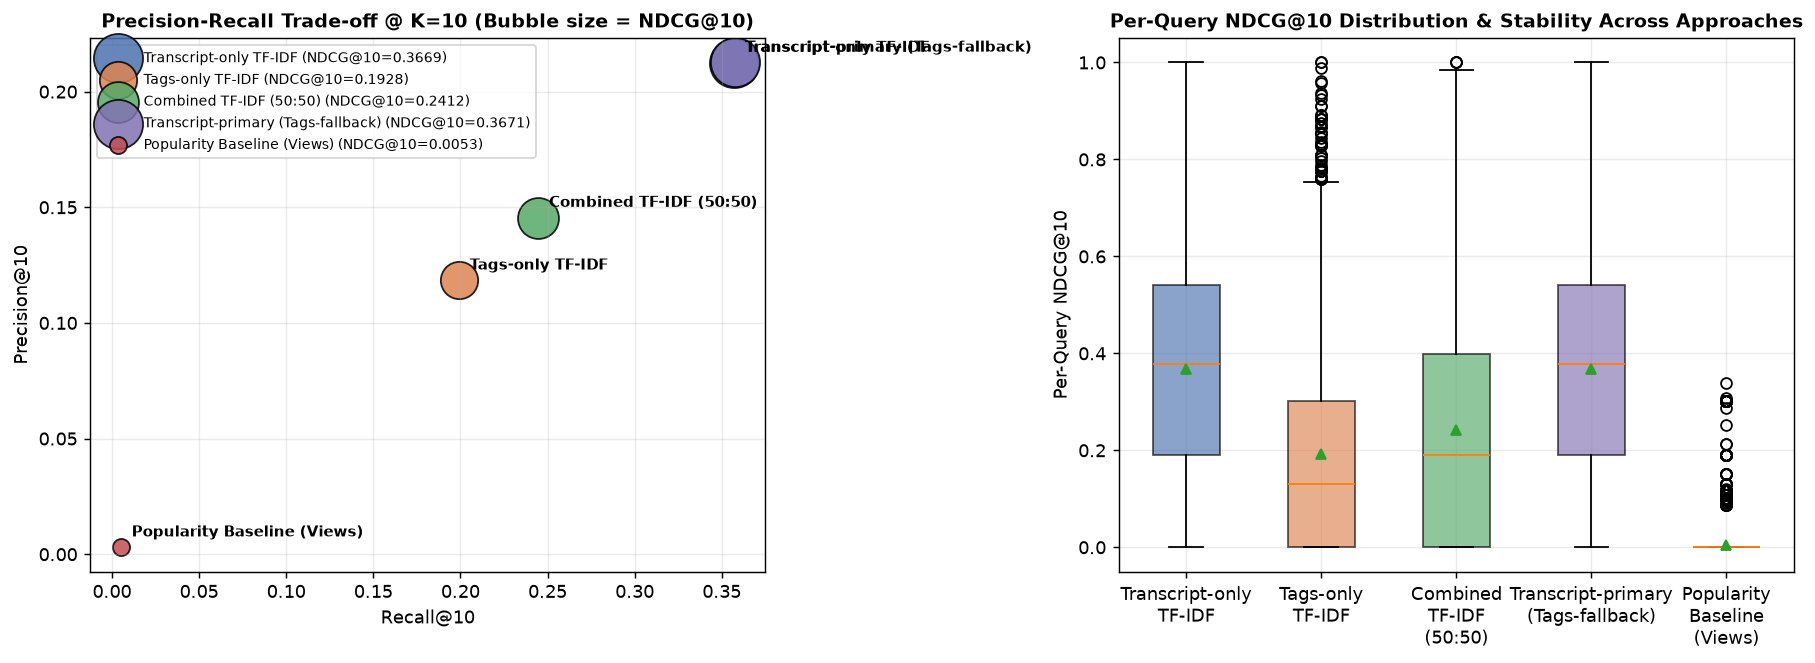

In [7]:
fig_dir = OUT_DIR / "figures"
for fname in sorted(p.name for p in fig_dir.glob("*.png")):
    print(f"--- {fname} ---")
    display(Image(filename=str(fig_dir / fname)))

## 8. Final Model Selection, Trade-Offs & Conclusions

### 8.1 Quantitative Findings ($N = 4,004$ Eligible Queries)
- **Transcript-primary (Tags-fallback)** achieves the highest performance across every evaluation metric (`Precision@5 = 0.3001`, `Recall@5 = 0.2523`, `NDCG@5 = 0.3412`, `MAP@5 = 0.2299`, `Precision@10 = 0.2126`, `Recall@10 = 0.3574`, `NDCG@10 = 0.3671`, `MAP@10 = 0.2310`, `Hit@10 = 0.8871`).
- **Transcript-only TF-IDF** matches it on the 3,999 transcript-bearing talks (`Precision@5 = 0.3000`, `NDCG@10 = 0.3669`, `Hit@10 = 0.8861`), but fails to generate similarity matches for the **5 empty-transcript talks** (`talk_id` 179, 1156, 1464, 2147, 2273).
- **Combined TF-IDF (50:50)** ranks third (`Precision@5 = 0.1932`, `NDCG@10 = 0.2412`), outperforming **Tags-only TF-IDF** (`Precision@5 = 0.1533`, `NDCG@10 = 0.1928`) by +26% relative Precision@5 and the **Popularity Baseline** (`Precision@5 = 0.0044`) by ~44×. However, giving coarse binary tags an equal 50% weight pulls tag-tie candidates ahead of deeper transcript matches.
- **Popularity Baseline (Views)** performs near zero because global popularity is non-personalized and ignores the query talk's topic completely.

### 8.2 Balanced Model Selection & Justification
**Selected Final Model: `Transcript-primary (Tags-fallback)`**
1. **Peak Ranking Accuracy:** Leads all 5 approaches on Precision, Recall, NDCG, and MAP at both $K=5$ and $K=10$.
2. **100% Catalog Coverage:** Seamlessly falls back to `Tags-only TF-IDF` for the 5 talks lacking transcripts, recovering valid tag-based recommendations without degrading performance on the 3,999 transcript-bearing talks.
3. **High Interpretability & Zero Data Leakage:** Recommendations are directly explainable via shared TF-IDF n-grams (or shared topic tags during fallback), and `related_talk_ids` is strictly isolated as an offline evaluation proxy.

### 8.3 Remaining Limitations
1. `related_talk_ids` are editorial proxy labels rather than live user click/watch feedback.
2. Lexical TF-IDF cannot match synonyms without shared words (future work: hybrid dense embeddings).
3. Collaborative filtering remains unimplemented due to the absence of user-level interaction logs.